In [1]:
print("Hello_World")

Hello_World


# Tokenization

## Step-1 : Word_Splitting

In [2]:
with open("the Verdict.txt","r",encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of characters:", len(raw_text))
print(raw_text[:99])

Total number of characters: 20758
I had always thought Jack Gisburn rather a cheap genius--though a

good fellow enough--so it was no


In [3]:
import re

text = "Hello, World. This, is a test."
result = re.split(r'(\s)', text)     # --> Split where white space encountered

print(result)

['Hello,', ' ', 'World.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


In [4]:
result = re.split(r'([,.]|\s)', text)

print(result)

['Hello', ',', '', ' ', 'World', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


In [5]:
result = [item for item in result if item.strip()]

print(result)                           # White spaces contains meaning too.

['Hello', ',', 'World', '.', 'This', ',', 'is', 'a', 'test', '.']


In [6]:
text = "Hello, world. Is this-- a test?"

result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [item for item in result if item.strip()]

print(result) 

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [7]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item for item in preprocessed if item.strip()]

print(preprocessed[:30])

['I', 'had', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


## Step-2 : Creating Token ID's

In [8]:
all_words = sorted(set(preprocessed))     #Contains only unique words
vocab_size = len(all_words)                 

print(vocab_size)

1145


In [9]:
# token --> token ID's
vocab = {token:integer for integer,token in enumerate(all_words)} 

In [10]:
for i, item in enumerate(vocab.items()):          #Coverted to tokens
    print(item)
    if i>=50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('AM', 12)
('Ah', 13)
('Among', 14)
('And', 15)
('Are', 16)
('Arrt', 17)
('As', 18)
('At', 19)
('Be', 20)
('Begin', 21)
('Burlington', 22)
('But', 23)
('By', 24)
('Carlo', 25)
('Chicago', 26)
('Claude', 27)
('Come', 28)
('Croft', 29)
('Destroyed', 30)
('Devonshire', 31)
('Don', 32)
('Dubarry', 33)
('Emperors', 34)
('End', 35)
('FELT', 36)
('Florence', 37)
('For', 38)
('Gallery', 39)
('Gideon', 40)
('Gisburn', 41)
('Gisburns', 42)
('Grafton', 43)
('Greek', 44)
('Grindle', 45)
('Grindles', 46)
('HAD', 47)
('HAS', 48)
('HAVE', 49)
('Had', 50)


In [11]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [
            item for item in preprocessed if item.strip()
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text    

In [12]:
tokenizer = SimpleTokenizerV1(vocab)

text = """It's the last he painted, you know,"
          Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[61, 2, 865, 1003, 616, 547, 761, 5, 1141, 611, 5, 1, 74, 7, 41, 866, 1123, 769, 809, 7]


In [13]:
tokenizer.decode(ids)

'It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

In [14]:
text = "Hello, do you like tea?"            #LARGE LANGUAGE MODELS
print(tokenizer.encode(text))

KeyError: 'Hello'

In [15]:
# Adding special context tokens --> <|unk|>,<|endoftext|>
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>","<|unk|>"])

vocab = {token:integer for integer,token in enumerate(all_tokens)}

In [16]:
len(vocab.items())

1147

In [17]:
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

('younger', 1142)
('your', 1143)
('yourself', 1144)
('<|endoftext|>', 1145)
('<|unk|>', 1146)


In [18]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'(<\|endoftext\|>|[,.:;?_!"()\']|--|\s)', text)
        preprocessed = [
            item for item in preprocessed if item.strip()
        ]
        preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text  

In [19]:
Tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like the tea?"
text2 = "In the sunlit terraces of the palace."

text = "<|endoftext|>".join((text1, text2))

print(text)

Hello, do you like the tea?<|endoftext|>In the sunlit terraces of the palace.


In [20]:
Tokenizer.encode(text)

[1146,
 5,
 369,
 1141,
 642,
 1003,
 990,
 10,
 1145,
 60,
 1003,
 971,
 999,
 737,
 1003,
 1146,
 7]

In [21]:
Tokenizer.decode(Tokenizer.encode(text))

'<|unk|>, do you like the tea? <|endoftext|> In the sunlit terraces of the <|unk|>.'

In [22]:
# [BOS],[EOS],[PAD] --> Byte-Pair Encoding (breaks word into subword units) 

# Byte-Pair-Encoder

In [23]:
print("Hello_World")

Hello_World


In [24]:
%pip install tiktoken

Note: you may need to restart the kernel to use updated packages.


In [25]:
import tiktoken

print(tiktoken.__version__)

0.14.0


In [26]:
import importlib
import tiktoken

print("tiktoken version:", importlib.metadata.version("tiktoken"))

tiktoken version: 0.14.0


In [27]:
tokenizer = tiktoken.get_encoding("gpt2")

In [28]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
    "of someunknownPlace."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


In [29]:
strings = tokenizer.decode(integers)

print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


# Creating Input-Target Pairs

In [30]:
with open("The Verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5765


In [31]:
enc_sample = enc_text[50:]

In [32]:
context_size = 4 #length of the input

x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]

print(f"x: {x}")
print(f"y:        {y}")

x: [30526, 257, 5527, 27075]
y:        [257, 5527, 27075, 11]


In [33]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(context,"----->",desired)

[30526] -----> 257
[30526, 257] -----> 5527
[30526, 257, 5527] -----> 27075
[30526, 257, 5527, 27075] -----> 11


In [34]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(tokenizer.decode(context),"----->",tokenizer.decode([desired]))

married ----->  a
married a ----->  rich
married a rich ----->  widow
married a rich widow -----> ,


## Implementing a Data_loaders

In [35]:
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length +1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__ (self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [36]:
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer 
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [37]:
with open("The Verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

In [38]:
import torch
print("PyTorch version:", torch.__version__)
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)

data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

PyTorch version: 2.13.0+cpu
[tensor([[  40,  550, 1464, 1807]]), tensor([[ 550, 1464, 1807, 3619]])]


In [39]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 550, 1464, 1807, 3619]]), tensor([[1464, 1807, 3619,  402]])]


In [40]:
dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\ntargets:\n", targets)

Inputs:
 tensor([[   40,   550,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   198],
        [  198, 11274,  5891,  1576],
        [  438,   568,   340,   373],
        [  645,  1049,  5975,   284],
        [  502,   284,  3285,   198]])

targets:
 tensor([[  550,  1464,  1807,  3619],
        [  402,   271, 10899,  2138],
        [  257,  7026, 15632,   438],
        [ 2016,   257,   198,   198],
        [11274,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   198,   198]])


# Token_Embeddings

## Creating Token Embeddings

In [41]:
input_ids = torch.tensor([2,3,5,1])

In [42]:
vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [43]:
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


In [44]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [45]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


## Positional Embeddings (Encoding Word Positions)

In [46]:
vocab_size = 50257
output_dim = 256

# token embedding layer {elements --> 50257*256}
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [47]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)

In [48]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   550,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   198],
        [  198, 11274,  5891,  1576],
        [  438,   568,   340,   373],
        [  645,  1049,  5975,   284],
        [  502,   284,  3285,   198]])

Inputs shape:
 torch.Size([8, 4])


In [49]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


In [50]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

In [51]:
pos_embeddings = pos_embedding_layer(torch.arange(max_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


In [52]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


## Implementing a simplified attention mechanism

In [53]:
import torch

inputs = torch.tensor(
    [[0.43, 0.15, 0.39], # Your     (x^1)
     [0.55, 0.87, 0.66], # journey  (x^2)
     [0.57, 0.85, 0.64], # starts   (x^3)
     [0.22, 0.58, 0.33], # with     (x^4)
     [0.77, 0.25, 0.10], # one      (x^5)
     [0.05, 0.80, 0.55]] # step     (x^6)
)

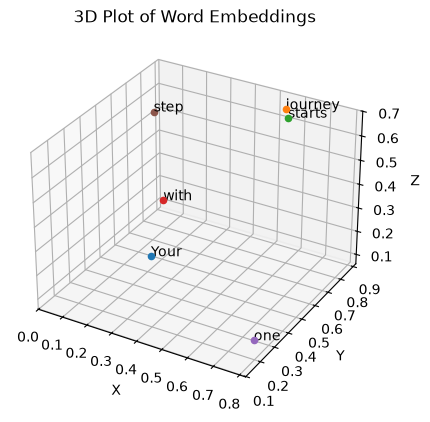

In [54]:
import matplotlib.pyplot as plt

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step', 'journey-context']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

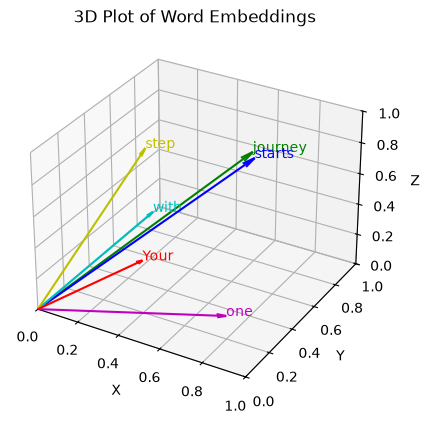

In [55]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'r']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings')
plt.show()

In [56]:
query = inputs[1]  # 2nd input token (journey) is the query

attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query) # dot product (transpose not need)

print(attn_scores_2)

tensor([0.6244, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [57]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()

print("Attention Weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention Weights: tensor([0.1002, 0.2399, 0.2368, 0.1353, 0.1135, 0.1744])
Sum: tensor(1.)


In [58]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attn_weights_2_naive = softmax_naive(attn_scores_2)

print("Attention weights:", attn_weights_2_naive)        # Inpretable btw words
print("Sum:", attn_weights_2_naive.sum())         

Attention weights: tensor([0.1036, 0.2475, 0.2427, 0.1290, 0.1126, 0.1645])
Sum: tensor(1.)


In [59]:
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1036, 0.2475, 0.2427, 0.1290, 0.1126, 0.1645])
Sum: tensor(1.)


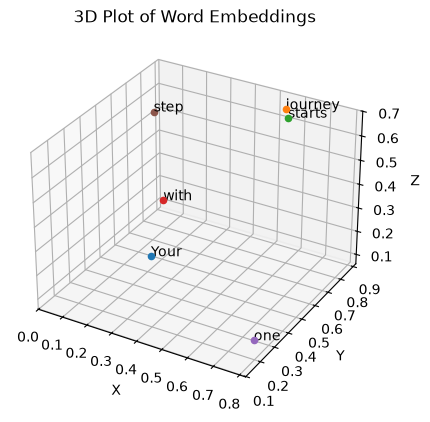

In [60]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each word embedding
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

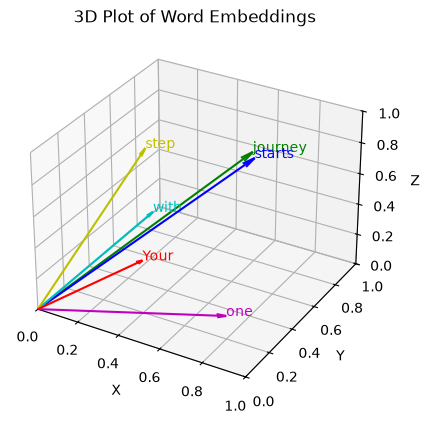

In [61]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'r']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings')
plt.show()

In [62]:
query = inputs[1] # 2nd input token is the query

context_vec_2 = torch.zeros(query.shape)
for i,x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i]*x_i

print(context_vec_2)

tensor([0.4423, 0.6718, 0.5035])


In [63]:
attn_scores = torch.empty(6, 6)            # slowed process --> 2 for loops
for i, x_i in enumerate(inputs):
   for j, x_j in enumerate(inputs):
       attn_scores[i, j] = torch.dot(x_i, x_j)
print(attn_scores)

tensor([[0.3595, 0.6244, 0.6222, 0.3103, 0.4076, 0.3560],
        [0.6244, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.6222, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.3103, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4076, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.3560, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [64]:
attn_scores = inputs @ inputs.T            # mutiplying 2 matrix --> Fast
print(attn_scores)

tensor([[0.3595, 0.6244, 0.6222, 0.3103, 0.4076, 0.3560],
        [0.6244, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.6222, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.3103, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4076, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.3560, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [65]:
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights)

tensor([[0.1515, 0.1974, 0.1970, 0.1442, 0.1589, 0.1510],
        [0.1036, 0.2475, 0.2427, 0.1290, 0.1126, 0.1645],
        [0.1049, 0.2463, 0.2418, 0.1291, 0.1152, 0.1627],
        [0.1244, 0.2120, 0.2091, 0.1495, 0.1291, 0.1759],
        [0.1463, 0.1973, 0.1990, 0.1377, 0.1893, 0.1305],
        [0.1088, 0.2259, 0.2201, 0.1469, 0.1022, 0.1961]])


In [66]:
row_2_sum = sum([0.1515, 0.1974, 0.1970, 0.1442, 0.1589, 0.1510])
print("Row 2 sum:", row_2_sum)
print("All row sums:", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [67]:
all_context_vecs = attn_weights @ inputs
print(all_context_vecs)

tensor([[0.4477, 0.6061, 0.4620],
        [0.4423, 0.6718, 0.5035],
        [0.4436, 0.6694, 0.5018],
        [0.4304, 0.6405, 0.4813],
        [0.4674, 0.5943, 0.4507],
        [0.4173, 0.6676, 0.4989]])


In [68]:
print("Previous 2nd context vector:", context_vec_2)

Previous 2nd context vector: tensor([0.4423, 0.6718, 0.5035])


# Attention mechanism with query, key & value

In [69]:
x_2 = inputs [1] #A
d_in = inputs.shape[1] #B
d_out = 2 #C

In [70]:
torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [71]:
print(W_query)

Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])


In [72]:
print(W_key)

Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]])


In [73]:
print(W_value)

Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]])


In [74]:
query_2 = x_2 @ W_query
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value
print(query_2)

tensor([0.4306, 1.4551])


In [75]:
print(key_2)

tensor([0.4433, 1.1419])


In [76]:
print(value_2)

tensor([0.3951, 1.0037])


In [77]:
keys = inputs @ W_key
values = inputs @ W_value
queries = inputs @ W_query

print("keys shape:", keys.shape)

print("values.shape", values.shape)

print("queries.shape", queries.shape)    # 3D --> 2D embedding space

keys shape: torch.Size([6, 2])
values.shape torch.Size([6, 2])
queries.shape torch.Size([6, 2])


In [78]:
keys_2 = keys[1] #A
attn_score_22 = query_2.dot(keys_2)
print(attn_score_22)

tensor(1.8524)


In [79]:
attn_scores_2 = query_2 @ keys.T # All attention scores for given query
print(attn_scores_2)

tensor([0.7027, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


In [80]:
attn_scores = queries @ keys.T # omega
print(attn_scores)

tensor([[0.3199, 0.8434, 0.8246, 0.4916, 0.2538, 0.7031],
        [0.7027, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [0.6938, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.3857, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.3388, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.4972, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]])


In [81]:
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)
print(d_k)

tensor([0.1057, 0.2382, 0.2313, 0.1379, 0.0954, 0.1915])
2


In [82]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.7742])


In [83]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):

    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value

        attn_scores = queries @ keys.T # omega
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )

        context_vec = attn_weights @ values
        return context_vec

In [84]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in , d_out)
print(sa_v1(inputs))

tensor([[0.2871, 0.7283],
        [0.3061, 0.7742],
        [0.3057, 0.7731],
        [0.2905, 0.7365],
        [0.2877, 0.7299],
        [0.2963, 0.7505]], grad_fn=<MmBackward0>)


In [85]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.7742])


In [86]:
class SelfAttention_v2(nn.Module):

    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        
        attn_scores = queries @ keys.T # omega
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )

        context_vec = attn_weights @ values
        return context_vec

In [87]:
torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0584,  0.0871],
        [-0.0568,  0.0900],
        [-0.0569,  0.0898],
        [-0.0588,  0.0868],
        [-0.0593,  0.0861],
        [-0.0579,  0.0882]], grad_fn=<MmBackward0>)


## Hiding Future Words with Casual-Attention

In [88]:
queries = sa_v2.W_query(inputs) #A
keys = sa_v2.W_key(inputs)
attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=1)
print(attn_weights)

tensor([[0.1731, 0.1679, 0.1681, 0.1611, 0.1705, 0.1593],
        [0.1798, 0.1709, 0.1713, 0.1541, 0.1715, 0.1523],
        [0.1796, 0.1709, 0.1712, 0.1543, 0.1714, 0.1525],
        [0.1736, 0.1694, 0.1696, 0.1597, 0.1688, 0.1589],
        [0.1722, 0.1691, 0.1692, 0.1610, 0.1680, 0.1606],
        [0.1762, 0.1699, 0.1701, 0.1575, 0.1701, 0.1562]],
       grad_fn=<SoftmaxBackward0>)


In [89]:
context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
print(mask_simple)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [90]:
masked_simple = attn_weights*mask_simple
print(masked_simple)

tensor([[0.1731, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1798, 0.1709, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1796, 0.1709, 0.1712, 0.0000, 0.0000, 0.0000],
        [0.1736, 0.1694, 0.1696, 0.1597, 0.0000, 0.0000],
        [0.1722, 0.1691, 0.1692, 0.1610, 0.1680, 0.0000],
        [0.1762, 0.1699, 0.1701, 0.1575, 0.1701, 0.1562]],
       grad_fn=<MulBackward0>)


In [91]:
row_sums = masked_simple.sum(dim=1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5127, 0.4873, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3442, 0.3276, 0.3282, 0.0000, 0.0000, 0.0000],
        [0.2583, 0.2520, 0.2522, 0.2375, 0.0000, 0.0000],
        [0.2051, 0.2014, 0.2015, 0.1917, 0.2002, 0.0000],
        [0.1762, 0.1699, 0.1701, 0.1575, 0.1701, 0.1562]],
       grad_fn=<DivBackward0>)


In [92]:
print(attn_scores)

tensor([[ 0.1026,  0.0588,  0.0608,  0.0007,  0.0806, -0.0153],
        [ 0.2439,  0.1723,  0.1751,  0.0259,  0.1771,  0.0085],
        [ 0.2406,  0.1703,  0.1731,  0.0259,  0.1745,  0.0090],
        [ 0.1373,  0.1024,  0.1036,  0.0186,  0.0973,  0.0122],
        [ 0.1129,  0.0874,  0.0882,  0.0177,  0.0786,  0.0144],
        [ 0.1783,  0.1270,  0.1290,  0.0198,  0.1290,  0.0078]],
       grad_fn=<MmBackward0>)


In [93]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.1026,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.2439, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.2406, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.1373, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.1129, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.1783, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]],
       grad_fn=<MaskedFillBackward0>)


In [94]:
attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5127, 0.4873, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3442, 0.3276, 0.3282, 0.0000, 0.0000, 0.0000],
        [0.2583, 0.2520, 0.2522, 0.2375, 0.0000, 0.0000],
        [0.2051, 0.2014, 0.2015, 0.1917, 0.2002, 0.0000],
        [0.1762, 0.1699, 0.1701, 0.1575, 0.1701, 0.1562]],
       grad_fn=<SoftmaxBackward0>)


## Masking Additional Attention Weights with Dropout

In [95]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5) #A
example = torch.ones(6,6) #B
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


In [96]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.6885, 0.6551, 0.6564, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.5040, 0.5044, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4029, 0.0000, 0.3835, 0.0000, 0.0000],
        [0.0000, 0.3398, 0.3403, 0.3150, 0.3403, 0.0000]],
       grad_fn=<MulBackward0>)


## Implementing a compact casual attention class

In [97]:
batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [98]:
class CausalAttention(nn.Module):

    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout) # New
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1)) #

    def forward(self, x):
        b, num_tokens, d_in = x.shape # New batch dimension b
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.transpose(1, 2) # Changed transpose
        attn_scores.masked_fill_(   # New, _ ops are in-place
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf) # :num_tokens to account for cases where the number of tokens in the batch is smaller then the context size
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )
        attn_weights = self.dropout(attn_weights) # New

        context_vec = attn_weights @ values
        return context_vec

In [99]:
torch.manual_seed(123)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs = ca(batch)
print("context_vecs.shape:", context_vecs.shape)

context_vecs.shape: torch.Size([2, 6, 2])


In [100]:
print(context_vecs)

tensor([[[-0.3459,  0.0326],
         [-0.5396, -0.0877],
         [-0.5992, -0.1253],
         [-0.5420, -0.1309],
         [-0.5326, -0.1369],
         [-0.5129, -0.1390]],

        [[-0.3459,  0.0326],
         [-0.5396, -0.0877],
         [-0.5992, -0.1253],
         [-0.5420, -0.1309],
         [-0.5326, -0.1369],
         [-0.5129, -0.1390]]], grad_fn=<UnsafeViewBackward0>)


## Extending Single Head Attention to Multi Head Attention

In [101]:
class MultiHeadAttentionWrapper(nn.Module):

    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention(d_in, d_out, context_length, dropout, qkv_bias)
            for _ in range(num_heads)]
        )

    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)

In [102]:
import torch

inputs = torch.tensor(
    [[0.43, 0.15, 0.39], # Your     (x^1)
     [0.55, 0.87, 0.66], # journey  (x^2)
     [0.57, 0.85, 0.64], # starts   (x^3)
     [0.22, 0.58, 0.33], # with     (x^4)
     [0.77, 0.25, 0.10], # one      (x^5)
     [0.05, 0.80, 0.55]] # step     (x^6)
)

batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [103]:
torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens
d_in, d_out = 3, 2
mha = MultiHeadAttentionWrapper(d_in,d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.3459,  0.0326,  0.3514,  0.1445],
         [-0.5396, -0.0877,  0.5225,  0.3303],
         [-0.5992, -0.1253,  0.5754,  0.3868],
         [-0.5420, -0.1309,  0.5164,  0.3637],
         [-0.5326, -0.1369,  0.5072,  0.3488],
         [-0.5129, -0.1390,  0.4876,  0.3511]],

        [[-0.3459,  0.0326,  0.3514,  0.1445],
         [-0.5396, -0.0877,  0.5225,  0.3303],
         [-0.5992, -0.1253,  0.5754,  0.3868],
         [-0.5420, -0.1309,  0.5164,  0.3637],
         [-0.5326, -0.1369,  0.5072,  0.3488],
         [-0.5129, -0.1390,  0.4876,  0.3511]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


## Implementing Multi-head attention with weight splits

In [104]:
# Causal_attention(masked) + Multi-head attention_wrapper = Multi-head attention

In [105]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                      diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a 'num_heads' dimensions
        # Unroll last dim: (b, num_tokens, d_out) --> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) --> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1,2)
        queries = queries.transpose(1,2)
        values = values.transpose(1,2)

        # Compute scaled dot-product attention (aka self-attention) with causal mask
        attn_scores = queries @ keys.transpose(2,3) # Dot product for each head

        # Original mask truncated to the number of tokens & converted boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)

        # Shape: (b, num_tokens, num_heads, heads_dim)
        context_vec = (attn_weights @ values).transpose(1,2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec) # optimal projection

        return context_vec

In [106]:
torch.manual_seed(123)

# Define the tensor with 3 rows & 6 columns
inputs = torch.tensor(
   [[0.43, 0.15, 0.89, 0.55, 0.87, 0.66], # Row 1
    [0.57, 0.85, 0.64, 0.22, 0.58, 0.33], # Row 2
    [0.77, 0.25, 0.10, 0.05, 0.80, 0.55]] # Row 3   
)

batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)

batch_size, context_length, d_in = batch.shape
d_out = 6
mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape", context_vecs.shape)

torch.Size([2, 3, 6])
tensor([[[ 0.1569, -0.0873,  0.0210,  0.0215, -0.3243, -0.2518],
         [ 0.1117, -0.0547,  0.0406, -0.0213, -0.3251, -0.2993],
         [ 0.1196, -0.0491,  0.0318, -0.0635, -0.2788, -0.2578]],

        [[ 0.1569, -0.0873,  0.0210,  0.0215, -0.3243, -0.2518],
         [ 0.1117, -0.0547,  0.0406, -0.0213, -0.3251, -0.2993],
         [ 0.1196, -0.0491,  0.0318, -0.0635, -0.2788, -0.2578]]],
       grad_fn=<ViewBackward0>)
context_vecs.shape torch.Size([2, 3, 6])


## Implemeting a GPT Model from scratch to generate text

In [107]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of atttention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

## GPT ARCHITECTURE PART 1: Dummy GPT Model Class

In [108]:
import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # Use a placeholder for LayerNorm
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        # Use a Placeholder for LayerNorm
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A Simple Placeholder

    def forward(self, x):
        # This block does nothing & just return its input.
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing & just return its input.
        return x

### Step 1 : Tokenization

In [109]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


### Step 2 : Create an Instance of DummyGPTModel

In [110]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)
logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6754, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


## GPT ARCHITECTURE PART 2: LAYER NORMALIZATION

In [111]:
torch.manual_seed(123)
batch_example = torch.randn(2,5) #A
layer = nn.Sequential(nn.Linear(5,6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [112]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [113]:
out_norm = (out - mean) / torch.sqrt(var)
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [0.0000e+00]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [114]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [115]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x-mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

In [116]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


## GPT Architecture Part-3: FEEDFORWARD NEURAL NETWORK WITH GELU ACTIVATION FXN

In [117]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

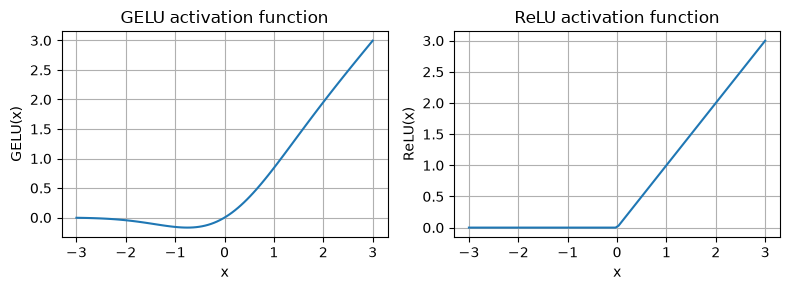

In [118]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some Sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8,3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU","ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [119]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of atttention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [120]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]), ## Exapnsion
            GELU(),                                        ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]), ## Contraction
        )

    def forward(self, x):
        return self.layers(x)

In [121]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2, 3, 768) #A
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


In [122]:
print(GPT_CONFIG_124M["emb_dim"])

768


## GPT Architecture part 4: ShortCut Connections 

In [123]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU()),           
        ])

    def forward(self, x):
        for layer in self.layers:
            # Compute the output of the current layer
            layer_output = layer(x)
            # Check if shortcut is applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output

        return x

In [124]:
layer_sizes = [3,3,3,3,3,1]
sample_input = torch.tensor([[1.,0.,-1.]])
torch.manual_seed(123) # specify random seed for the initial weights for reproducibility
model_without_shortcut = ExampleDeepNeuralNetwork(
layer_sizes, use_shortcut=False
)

In [125]:
def print_gradients(model, x):
    #Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the traget and an output are
    loss = nn.MSELoss()
    loss = loss(output, target)

    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [126]:
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


In [127]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896989583969116
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


## GPT Architecture Part 5: Coding Attention & Linear Layers in a  Transformer Block

In [128]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of atttention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

### The Building Blocks: Layer Normalization, GELU & Feed-Forward Neural Network

In [129]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x-mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]), ## Exapnsion
            GELU(),                                        ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]), ## Contraction
        )

    def forward(self, x):
        return self.layers(x)

In [130]:
class TransformerBlock(nn.Module):
   def __init__(self, cfg):
       super().__init__()
       self.att = MultiHeadAttention(
           d_in=cfg["emb_dim"],
           d_out=cfg["emb_dim"],
           context_length=cfg["context_length"],
           num_heads=cfg["n_heads"], 
           dropout=cfg["drop_rate"],
           qkv_bias=cfg["qkv_bias"])
       self.ff = FeedForward(cfg)
       self.norm1 = LayerNorm(cfg["emb_dim"])
       self.norm2 = LayerNorm(cfg["emb_dim"])
       self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
       
   def forward(self, x):
       # Shortcut connection for attention block                                             
       shortcut = x
       x = self.norm1(x)
       x = self.att(x)   # Shape [batch_size, num_tokens, emb_size]
       x = self.drop_shortcut(x)
       x = x + shortcut  # Add the original input back

       # Shortcut connection for feed forward block
       shortcut = x                                           
       x = self.norm2(x)
       x = self.ff(x)
       x = self.drop_shortcut(x)                                   
       x = x + shortcut   # Add the original input back
       
       return x

In [131]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768) 
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


### GPT ARCHITECTURE PART 6: Entire GPT Model Architecture Implementataion

In [132]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of atttention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [133]:
import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # Use a placeholder for LayerNorm
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        # Use a Placeholder for LayerNorm
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A Simple Placeholder

    def forward(self, x):
        # This block does nothing & just return its input.
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing & just return its input.
        return x

In [134]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x-mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]), ## Exapnsion
            GELU(),                                        ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]), ## Contraction
        )

    def forward(self, x):
        return self.layers(x)

In [135]:
class TransformerBlock(nn.Module):
   def __init__(self, cfg):
       super().__init__()
       self.att = MultiHeadAttention(
           d_in=cfg["emb_dim"],
           d_out=cfg["emb_dim"],
           context_length=cfg["context_length"],
           num_heads=cfg["n_heads"], 
           dropout=cfg["drop_rate"],
           qkv_bias=cfg["qkv_bias"])
       self.ff = FeedForward(cfg)
       self.norm1 = LayerNorm(cfg["emb_dim"])
       self.norm2 = LayerNorm(cfg["emb_dim"])
       self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
       
   def forward(self, x):
       # Shortcut connection for attention block                                             
       shortcut = x
       x = self.norm1(x)
       x = self.att(x)   # Shape [batch_size, num_tokens, emb_size]
       x = self.drop_shortcut(x)
       x = x + shortcut  # Add the original input back

       # Shortcut connection for feed forward block
       shortcut = x                                           
       x = self.norm2(x)
       x = self.ff(x)
       x = self.drop_shortcut(x)                                   
       x = x + shortcut   # Add the original input back
       
       return x

In [136]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # transformer block
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        # for LayerNorm
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [137]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.0312,  0.7345,  0.0314,  ...,  0.2266,  0.4904, -0.1199],
         [ 0.0501, -0.7704, -0.5094,  ..., -0.4264,  0.3134, -0.3193],
         [ 1.0896,  0.1705,  0.0189,  ...,  0.1061, -0.6477,  0.0346],
         [-0.9491,  0.4275, -0.1798,  ...,  0.6825,  0.3292,  0.0160]],

        [[-0.1103,  0.1539, -0.1568,  ...,  0.4551,  0.3328, -0.7656],
         [ 0.0196, -0.0002,  0.0025,  ...,  0.9207,  0.1673,  0.5939],
         [ 0.8432,  0.9212, -0.1725,  ...,  0.8271,  0.5152, -0.1054],
         [-0.1324,  0.3367,  0.5401,  ...,  1.3945, -0.2461, -0.0011]]],
       grad_fn=<UnsafeViewBackward0>)


In [138]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


In [139]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


In [140]:
total_params_gpt2 = total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

Number of trainable parameters considering weight tying: 124,412,160


In [141]:
total_size_bytes = total_params * 4 # Each parameter takes about 4 bytes
total_size_mb = total_size_bytes / (1024*1024) #B
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


### GPT ARCHITECTURE PART 7: Generating text from output tokens

In [142]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    
    # Input batch:
    # tensor([[6109, 3626, 6100,  345],
    #       [6109, 1110, 6622,  257]])
    
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the spported context size
        # E.g., if LLM supports only 5 tokens, & the context size is 10
        # then only the last 5 tokens are used in context
        idx_cond = idx[:,-context_size:]

        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)   ### batch, n_tokens, vocab_size

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) become (batch, vocab_size)
        logits = logits[:,-1,:]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1) # (batch, n_tokens+1)

    return idx

In [143]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0) #A
print("encoded_tensor.sahpe:", encoded_tensor.shape) #(batch_size,tokens)

encoded: [15496, 11, 314, 716]
encoded_tensor.sahpe: torch.Size([1, 4])


In [144]:
model.eval() #A
out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


In [145]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text) # it's random because we haven't trained it yet (whole 124M parameters)

Hello, I am Featureiman Byeswickattribute argue


## Genrating Text

In [146]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 256, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of atttention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();    # Disable dropout during inference

In [147]:
import tiktoken

def text_to_token_ids(text, tokenizer):
   encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
   encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
   return encoded_tensor
    
def token_ids_to_text(token_ids, tokenizer):
   flat = token_ids.squeeze(0) # remove batch dimension
   return tokenizer.decode(flat.tolist())
    
start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
   model=model,
   idx=text_to_token_ids(start_context, tokenizer),
   max_new_tokens=10,
   context_size=GPT_CONFIG_124M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


### Calculating the text generation loss: cross-entropy & Perplexity

In [148]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40    ,1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [107,  588, 11311]])  # " really like chocolate"]

In [149]:
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1) # Probability of each token in vocabulary
print(probas.shape)

torch.Size([2, 3, 50257])


In [150]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True) # (-1) means along the column
print("Token IDs:\n", token_ids)                 

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


In [151]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


In [152]:
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)
text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([0.0001, 0.0000, 0.0000])
Text 2: tensor([0.0000, 0.0001, 0.0000])


In [153]:
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)

tensor([ -9.5042, -10.3796, -11.3677, -10.1492,  -9.7764, -12.2561])


In [154]:
avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

tensor(-10.5722)


In [155]:
neg_avg_log_probas = avg_log_probas * -1
print(neg_avg_log_probas)

tensor(10.5722)


In [156]:
print("Logits shape:", logits.shape)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


In [157]:
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()
print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


In [158]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.5722)


In [159]:
perplexity = torch.exp(loss)                # perplexity = e^(loss)
print(perplexity)

tensor(39034.1875)


### Calculating the training & validation set losses

In [160]:
with open("the Verdict.txt","r",encoding="utf-8") as f:
    text_data = f.read()

print("Total number of characters:", len(raw_text))
print(text_data[:99])

Total number of characters: 20758
I had always thought Jack Gisburn rather a cheap genius--though a

good fellow enough--so it was no


In [161]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")        # Byte-pair encoder

In [162]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 20758
Tokens: 5765


### Implementing the DataLoader:

In [163]:
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length +1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__ (self, idx):
        return self.input_ids[idx], self.target_ids[idx]

        

def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer 
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [164]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 256, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of atttention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [165]:
# train/validation ration

train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
   train_data,
   batch_size=2,
   max_length=GPT_CONFIG_124M["context_length"],
   stride=GPT_CONFIG_124M["context_length"],
   drop_last=True,
   shuffle=True,
   num_workers=0
)

val_loader = create_dataloader_v1(
   val_data,
   batch_size=2,
   max_length=GPT_CONFIG_124M["context_length"],
   stride=GPT_CONFIG_124M["context_length"],
   drop_last=False,
   shuffle=False,
   num_workers=0
)

In [166]:
# Sanity check

if total_tokens * (train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the training loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "increase the `training_ratio`")

if total_tokens * (1-train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the validation loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "decrease the `training_ratio`")

In [167]:
print("Train loader:")
for x, y in train_loader:
   print(x.shape, y.shape)
    
print("\nValidation loader:")
for x, y in val_loader:
   print(x.shape, y.shape)

print(len(train_loader))
print(len(val_loader))

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])
10
1


In [168]:
# Loading part
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 5120
Validation tokens: 512
All tokens: 5632


In [169]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # transformer block
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        # for LayerNorm
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [170]:
def calc_loss_batch(input_batch, target_batch, model, device):
   input_batch, target_batch = input_batch.to(device), target_batch.to(device) #A
   logits = model(input_batch)
   loss = torch.nn.functional.cross_entropy(
       logits.flatten(0, 1), target_batch.flatten()
   )
   return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)                            
    else:
        # Reduce the number of batches to match the total number of batches in the data loader if num_batches 
        # exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))          
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()                           
        else:
            break
    return total_loss / num_batches                               

In [171]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

with torch.no_grad():                                             
    train_loss = calc_loss_loader(train_loader, model, device)  
    
val_loss = calc_loss_loader(val_loader, model, device)
print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.970044422149659
Validation loss: 10.984174728393555


# Training loop for LLM

In [233]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                      eval_freq, eval_iter, start_context, tokenizer):

    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []      
    tokens_seen, global_step = 0, -1

    # Main training loop 
    for epoch in range(num_epochs):                               
       model.train()  # Set model to training mode
        
       for input_batch, target_batch in train_loader:
           optimizer.zero_grad() # Reset loss gradients from previus batch iteration
           loss = calc_loss_batch(input_batch, target_batch, model, device)
           loss.backward()    # Calculate loss gradients
           optimizer.step()    # Update model weights using loss gradients
           tokens_seen += input_batch.numel() # Returns the total number of elements (or tokens) in the
           global_step += 1

           # Optional evalution step
           if global_step % eval_freq == 0:                    
               train_loss, val_loss = evaluate_model(
                   model, train_loader, val_loader, device, eval_iter)
               train_losses.append(train_loss)
               val_losses.append(val_loss)
               track_tokens_seen.append(tokens_seen)
               print(f"Ep {epoch+1} (Step {global_step:06d}): "
                     f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

       # Print a sample text after each epoch       
       generate_and_print_sample(                               
           model, tokenizer, device, start_context
       )
    return train_losses, val_losses, track_tokens_seen

In [234]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
   model.eval()                                                  
   with torch.no_grad():                                         
       train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
       val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
   model.train()
   return train_loss, val_loss

In [235]:
def generate_and_print_sample(model, tokenizer, device, start_context):
   model.eval()
   context_size = model.pos_emb.weight.shape[0]
   encoded = text_to_token_ids(start_context, tokenizer).to(device)
   with torch.no_grad():
       token_ids = generate_text_simple(
           model=model, idx=encoded,
           max_new_tokens=50, context_size=context_size
       )
       decoded_text = token_ids_to_text(token_ids, tokenizer)
       print(decoded_text.replace("\n", " "))  # Compact print format
   model.train()

In [175]:
import time
start_time = time.time()

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
model, train_loader, val_loader, optimizer, device,
num_epochs=num_epochs, eval_freq=5, eval_iter=1,
start_context="Every effort moves you", tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time-start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 9.437, Val loss 9.450
Ep 1 (Step 000005): Train loss 7.529, Val loss 7.939
Every effort moves you                                                  
Ep 2 (Step 000010): Train loss 6.332, Val loss 6.821
Ep 2 (Step 000015): Train loss 6.079, Val loss 6.401
Every effort moves you,,,,,, and                                           
Ep 3 (Step 000020): Train loss 5.729, Val loss 6.343
Ep 3 (Step 000025): Train loss 5.509, Val loss 6.295
Every effort moves you, and                                                
Ep 4 (Step 000030): Train loss 5.462, Val loss 6.333
Ep 4 (Step 000035): Train loss 5.260, Val loss 6.216
Every effort moves you, and                                                
Ep 5 (Step 000040): Train loss 4.955, Val loss 6.298
Ep 5 (Step 000045): Train loss 4.761, Val loss 6.225
Every effort moves you, with a                                               
Ep 6 (Step 000050): Train loss 3.332, Val loss 6.092
Ep 6 (Step 000055): Train loss 3.797, 

## DECODING STRATEGIES TO CONTROL RANDOMNESS

In [195]:
model.to("cpu")
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 1024)
  (pos_emb): Embedding(1024, 1024)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=1024, out_features=1024, bias=True)
        (W_key): Linear(in_features=1024, out_features=1024, bias=True)
        (W_value): Linear(in_features=1024, out_features=1024, bias=True)
        (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=1024, out_features=4096, bias=True)
          (1): GELU()
          (2): Linear(in_features=4096, out_features=1024, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(i

In [196]:
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves youaround LF Ethernet Motorsport� managerial Vintage RodrigoSw Scientist populate tied stealth incentivronics liquor Compared privat resonate presents Brigade1500 chestsCre talent


### Decoding Strategy 1: Temprature Scaling

In [197]:
vocab = { 
   "closer": 0,
   "every": 1, 
   "effort": 2, 
   "forward": 3,
   "inches": 4,
   "moves": 5, 
   "pizza": 6,
   "toward": 7,
   "you": 8,
} 
inverse_vocab = {v: k for k, v in vocab.items()}

In [198]:
next_token_logits = torch.tensor(
   [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [199]:
probas = torch.softmax(next_token_logits, dim=0)

print(probas)

next_token_id = torch.argmax(probas).item()

print(next_token_id)

print(inverse_vocab[next_token_id])

tensor([0.0609, 0.0016, 0.0001, 0.5721, 0.0034, 0.0001, 0.0001, 0.3576, 0.0040])
3
forward


In [200]:
def print_sampled_tokens(probas):
    torch.manual_seed(123)         # Manual seed for reproducibility
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")


print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


In [201]:
def softmax_with_temperature(logits, temperature):
   scaled_logits = logits / temperature
   return torch.softmax(scaled_logits, dim=0)

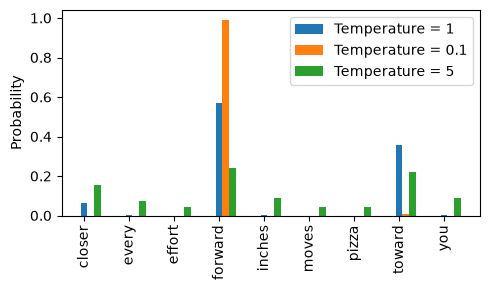

In [202]:
temperatures = [1, 0.1, 5]                                        
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]
x = torch.arange(len(vocab))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
   rects = ax.bar(x + i * bar_width, scaled_probas[i], 
                  bar_width, label=f'Temperature = {T}')
ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

### Decoding Strategy 2 : Top-k Sampling

In [203]:
next_token_logits = torch.tensor(
   [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [204]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)
print("Top logits:", top_logits)
print("Top positions:", top_pos)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


In [205]:
new_logits = torch.where(
   condition=next_token_logits < top_logits[-1],                 
   input=torch.tensor(float('-inf')),                           
   other=next_token_logits                                       
)
print(new_logits)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])


In [206]:
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


### Merge Temprature Scaling & Top-k Sampling

In [207]:
def generate(model, idx, max_new_tokens, context_size,
             temperature=1.0, top_k=None, eos_id=None):

    # Generate one token at a time
    for _ in range(max_new_tokens):

        # Keep only the most recent context_size tokens
        idx_cond = idx[:, -context_size:]

        # Get model predictions
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        logits = logits[:, -1, :]

        # Top-k sampling
        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]

            logits = torch.where(
                logits < min_val,
                torch.tensor(float('-inf')).to(logits.device),
                logits
            )

        # Temperature scaling
        if temperature > 0.0:
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)

            # Sample from probability distribution
            idx_next = torch.multinomial(probs, num_samples=1)

        else:
            # Greedy selection
            idx_next = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        # Stop if EOS token is generated
        if eos_id is not None and idx_next.item() == eos_id:
            break

        # Add generated token to sequence
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [208]:
torch.manual_seed(123)
token_ids = generate(
   model=model,
   idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
   max_new_tokens=15,
   context_size=GPT_CONFIG_124M["context_length"],
   top_k=25,
   temperature=1.4
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you Johnston broaderNULL Blindmorning LINK Incbacked203 programmed exitFOTextColorgets documentaries


## Saving & load model weights

In [209]:
model = GPTModel(GPT_CONFIG_124M)
torch.save(model.state_dict(), "model.pth")

In [210]:
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth"))
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features

In [211]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)

In [212]:
checkpoint = torch.load("model_and_optimizer.pth")
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();

## Loading pretrained weights from OpenAI 

In [213]:
pip install tensorflow>=2.15.0 tqdm>=4.66

Note: you may need to restart the kernel to use updated packages.


In [214]:
import tensorflow as tf
import tqdm

print("TensorFlow version:", tf.__version__ )
print("tqdm version:", tqdm.__version__)

TensorFlow version: 2.21.0
tqdm version: 4.70.1


In [215]:
from gpt_download3 import download_and_load_gpt2

In [216]:
settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\checkpoint


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\encoder.json


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\hparams.json


... (4 outputs left out)

C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\model.ckpt.meta


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\vocab.bpe


In [217]:
print("Settings:", settings)
print("Parameter dictionary keys:", params.keys())

Settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}
Parameter dictionary keys: dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


In [218]:
print(params["wte"])
print("Token embedding weight tensor dimensions:", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
Token embedding weight tensor dimensions: (50257, 768)


In [219]:
# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {
        "emb_dim": 768,
        "n_layers": 12,
        "n_heads": 12
    },
    "gpt2-medium (355M)": {
        "emb_dim": 1024,
        "n_layers": 24,
        "n_heads": 16
    },
    "gpt2-large (774M)": {
        "emb_dim": 1280,
        "n_layers": 36,
        "n_heads": 20
    },
    "gpt2-xl (1558M)": {
        "emb_dim": 1600,
        "n_layers": 48,
        "n_heads": 25
    }
}

model_name = "gpt2-small (124M)"

NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])

In [220]:
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})
gpt = GPTModel(NEW_CONFIG)
gpt.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

In [221]:
def assign(left, right):
   if left.shape != right.shape:
       raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
   return torch.nn.Parameter(torch.tensor(right))

In [222]:
import numpy as np
def load_weights_into_gpt(gpt, params):
   gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe']) #A
   gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
   
   for b in range(len(params["blocks"])):                        #B
       q_w, k_w, v_w = np.split(                                 #C
           (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
       gpt.trf_blocks[b].att.W_query.weight = assign(
           gpt.trf_blocks[b].att.W_query.weight, q_w.T)
       gpt.trf_blocks[b].att.W_key.weight = assign(
           gpt.trf_blocks[b].att.W_key.weight, k_w.T)
       gpt.trf_blocks[b].att.W_value.weight = assign(
           gpt.trf_blocks[b].att.W_value.weight, v_w.T)
       
       q_b, k_b, v_b = np.split(
           (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
       gpt.trf_blocks[b].att.W_query.bias = assign(
           gpt.trf_blocks[b].att.W_query.bias, q_b)
       gpt.trf_blocks[b].att.W_key.bias = assign(
           gpt.trf_blocks[b].att.W_key.bias, k_b)
       gpt.trf_blocks[b].att.W_value.bias = assign(
           gpt.trf_blocks[b].att.W_value.bias, v_b)
       
       gpt.trf_blocks[b].att.out_proj.weight = assign(
           gpt.trf_blocks[b].att.out_proj.weight, 
           params["blocks"][b]["attn"]["c_proj"]["w"].T)
       gpt.trf_blocks[b].att.out_proj.bias = assign(
           gpt.trf_blocks[b].att.out_proj.bias, 
           params["blocks"][b]["attn"]["c_proj"]["b"])
       
       gpt.trf_blocks[b].ff.layers[0].weight = assign(
           gpt.trf_blocks[b].ff.layers[0].weight, 
           params["blocks"][b]["mlp"]["c_fc"]["w"].T)
       gpt.trf_blocks[b].ff.layers[0].bias = assign(
           gpt.trf_blocks[b].ff.layers[0].bias, 
           params["blocks"][b]["mlp"]["c_fc"]["b"])
       
       gpt.trf_blocks[b].ff.layers[2].weight = assign(
           gpt.trf_blocks[b].ff.layers[2].weight, 
           params["blocks"][b]["mlp"]["c_proj"]["w"].T)
       gpt.trf_blocks[b].ff.layers[2].bias = assign(
           gpt.trf_blocks[b].ff.layers[2].bias, 
           params["blocks"][b]["mlp"]["c_proj"]["b"])
       
       gpt.trf_blocks[b].norm1.scale = assign(
           gpt.trf_blocks[b].norm1.scale, 
           params["blocks"][b]["ln_1"]["g"])
       gpt.trf_blocks[b].norm1.shift = assign(
           gpt.trf_blocks[b].norm1.shift, 
           params["blocks"][b]["ln_1"]["b"])
       
       gpt.trf_blocks[b].norm2.scale = assign(
           gpt.trf_blocks[b].norm2.scale, 
           params["blocks"][b]["ln_2"]["g"])
       gpt.trf_blocks[b].norm2.shift = assign(
           gpt.trf_blocks[b].norm2.shift, 
           params["blocks"][b]["ln_2"]["b"])
       
   gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
   gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
   gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"]) #D

In [223]:
load_weights_into_gpt(gpt, params)
gpt.to(device)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

In [224]:
torch.manual_seed(123)
token_ids = generate(
   model=gpt,
   idx=text_to_token_ids("Every effort moves you", tokenizer),
   max_new_tokens=25,
   context_size=NEW_CONFIG["context_length"],
   top_k=50,
   temperature=1.5
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you toward finding an ideal new way to practice something!

What makes us want to be on top of that?




# Fine-tunning for Classification

## DOWNLOADING DATASET

In [206]:
import urllib.request
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
   if data_file_path.exists():
       print(f"{data_file_path} already exists. Skipping download and extraction.")
       return
       
   with urllib.request.urlopen(url) as response:                 
       with open(zip_path, "wb") as out_file:
           out_file.write(response.read())
           
   with zipfile.ZipFile(zip_path, "r") as zip_ref:               
       zip_ref.extractall(extracted_path)
       
   original_file_path = Path(extracted_path) / "SMSSpamCollection"
   os.rename(original_file_path, data_file_path)                 
   print(f"File downloaded and saved as {data_file_path}")
    
download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)

sms_spam_collection\SMSSpamCollection.tsv already exists. Skipping download and extraction.


In [207]:
import pandas as pd
df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
df   

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [208]:
print(df["Label"].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


In [209]:
def create_balanced_dataset(df):
    
    num_spam = df[df["Label"] == "spam"].shape[0]         # Count the instances of "spam"     
    ham_subset = df[df["Label"] == "ham"].sample(num_spam, random_state=123)    # Randomly sample "ham" instances to match the number of "spam" instances
    balanced_df = pd.concat([ham_subset, df[df["Label"] == "spam"]])    # Combine ham "subset" with "spam"
    return balanced_df

balanced_df = create_balanced_dataset(df)
print(balanced_df["Label"].value_counts())

Label
ham     747
spam    747
Name: count, dtype: int64


In [210]:
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1})

In [211]:
def random_split(df, train_frac, validation_frac):
    # Shuffle the entire DataFrame
    df = df.sample(frac=1, random_state=123).reset_index(drop=True)

    # Calculate split indices
    train_end = int(len(df) * train_frac)                         
    validation_end = train_end + int(len(df) * validation_frac)

    # Split the DataFrame
    train_df = df[:train_end]
    validation_df = df[train_end:validation_end]
    test_df = df[validation_end:]

    return train_df, validation_df, test_df

# test size is implied to be 0.2 as the remainder
train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1) 

In [212]:
train_df.to_csv("train.csv", index=None)
validation_df.to_csv("validation.csv", index=None)
test_df.to_csv("test.csv", index=None)

## CREATING DATALOADERS

In [213]:
import torch
from torch.utils.data import Dataset


class SpamDataset(Dataset):
   def __init__(self, csv_file, tokenizer, max_length=None, pad_token_id=50256):
       self.data = pd.read_csv(csv_file)
       
       # Pre-tokenize texts
       self.encoded_texts = [
           tokenizer.encode(text) for text in self.data["Text"]
       ]
       if max_length is None:
           self.max_length = self._longest_encoded_length()
       else:
           self.max_length = max_length
           
           # Truncate sequences if they are longer than max_length
           self.encoded_texts = [
               encoded_text[:self.max_length]
               for encoded_text in self.encoded_texts
           ]
           
           # Pad sequences to the longest sequence
       self.encoded_texts = [
           encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
           for encoded_text in self.encoded_texts
       ]
   def __getitem__(self, index):
       encoded = self.encoded_texts[index]
       label = self.data.iloc[index]["Label"]
       return (
           torch.tensor(encoded, dtype=torch.long),
           torch.tensor(label, dtype=torch.long)
       )
    
   def __len__(self):
        return len(self.data)
        
   def _longest_encoded_length(self):
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length

In [214]:
train_dataset = SpamDataset(
    csv_file="train.csv",
    max_length=None,
    tokenizer=tokenizer
)

print(train_dataset.max_length)

120


In [215]:
val_dataset = SpamDataset(
    csv_file="validation.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)
test_dataset = SpamDataset(
    csv_file="test.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

In [216]:
from torch.utils.data import DataLoader


num_workers = 0                  # This setting ensures compatibility with most computers                                             
batch_size = 8
torch.manual_seed(123)


train_loader = DataLoader(
   dataset=train_dataset,
   batch_size=batch_size,
   shuffle=True,
   num_workers=num_workers,       # for Parallel Processing
   drop_last=True,
)

val_loader = DataLoader(
   dataset=val_dataset,
   batch_size=batch_size,
   num_workers=num_workers,
   drop_last=False,
)

test_loader = DataLoader(
   dataset=test_dataset,
   batch_size=batch_size,
   num_workers=num_workers,
   drop_last=False,
)

In [217]:
for input_batch, target_batch in train_loader:
   pass
print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)

Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])


In [218]:
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

130 training batches
19 validation batches
38 test batches


## INITIALIZING MODEL WITH PRETRAINED WEIGHTS

In [219]:
CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"
BASE_CONFIG = {
   "vocab_size": 50257,     # Vocabulary size
   "context_length": 1024,  # Context length
   "drop_rate": 0.0,        # Dropout rate
   "qkv_bias": True         # Query-key-value bias
}
model_configs = {
   "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
   "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
   "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
   "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

assert train_dataset.max_length <= BASE_CONFIG["context_length"], (
   f"Dataset length {train_dataset.max_length} exceeds model's context "
   f"length {BASE_CONFIG['context_length']}. Reinitialize data sets with "
   f"`max_length={BASE_CONFIG['context_length']}`"
)

In [220]:
model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")

from gpt_download3 import download_and_load_gpt2

settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\checkpoint


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\encoder.json


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\hparams.json


... (4 outputs left out)

C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\model.ckpt.meta


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\124M\vocab.bpe


In [221]:
text_1 = "Every effort moves you"
token_ids = generate_text_simple(
   model=model,
   idx=text_to_token_ids(text_1, tokenizer),
   max_new_tokens=15,
   context_size=BASE_CONFIG["context_length"]
)
print(token_ids_to_text(token_ids, tokenizer))

Every effort moves you forward.

The first step is to understand the importance of your work


In [222]:
text_2 = (
   "Is the following text 'spam'? Answer with 'yes' or 'no':"
   " 'You are a winner you have been specially"
   " selected to receive $1000 cash or a $2000 award.'"
)

token_ids = generate_text_simple(
   model=model,
   idx=text_to_token_ids(text_2, tokenizer),
   max_new_tokens=23,
   context_size=BASE_CONFIG["context_length"]
)

print(token_ids_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner


## Adding a classification head

In [223]:
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

In [224]:
for param in model.parameters():
   param.requires_grad = False

In [225]:
torch.manual_seed(123)

num_classes = 2
model.out_head = torch.nn.Linear(
  in_features=BASE_CONFIG["emb_dim"], 
   out_features=num_classes
)

In [226]:
for param in model.trf_blocks[-1].parameters():
    param.requires_grad = True
    
for param in model.final_norm.parameters():
    param.requires_grad = True

In [227]:
inputs = tokenizer.encode("Do you have time")
inputs = torch.tensor(inputs).unsqueeze(0)
print("Inputs:", inputs)
print("Inputs dimensions:", inputs.shape) # shape: (batch_size, num_tokens)

Inputs: tensor([[5211,  345,  423,  640]])
Inputs dimensions: torch.Size([1, 4])


In [228]:
with torch.no_grad():
   outputs = model(inputs)
    
print("Outputs:\n", outputs)
print("Outputs dimensions:", outputs.shape) # shape: (batch_size, num_tokens, num_classes)

Outputs:
 tensor([[[-1.5854,  0.9904],
         [-3.7235,  7.4548],
         [-2.2661,  6.6049],
         [-3.5983,  3.9902]]])
Outputs dimensions: torch.Size([1, 4, 2])


In [229]:
print("Last output token:", outputs[:, -1, :])  # Contains max info.

Last output token: tensor([[-3.5983,  3.9902]])


## Calculate the classification loss & accuracy

In [230]:
probas = torch.softmax(outputs[:, -1, :], dim=-1)
label = torch.argmax(probas)
print("Class label:", label.item())

Class label: 1


In [231]:
logits = outputs[:, -1, :]
label = torch.argmax(logits)
print("Class label:", label.item())

Class label: 1


In [232]:
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
   model.eval()
   correct_predictions, num_examples = 0, 0
    
   if num_batches is None:
       num_batches = len(data_loader)
   else:
       num_batches = min(num_batches, len(data_loader))
   for i, (input_batch, target_batch) in enumerate(data_loader):
       if i < num_batches:
           input_batch, target_batch = input_batch.to(device), target_batch.to(device)
           with torch.no_grad():
               logits = model(input_batch)[:, -1, :]       #Logits of last output tokens
           predicted_labels = torch.argmax(logits, dim=-1)
           
           num_examples += predicted_labels.shape[0]
           correct_predictions += (predicted_labels == target_batch).sum().item()
       else:
           break
   return correct_predictions / num_examples

In [234]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
torch.manual_seed(123)

train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [235]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)[:, -1, :]  # Logits of last output token
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

In [236]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
   total_loss = 0.
   if len(data_loader) == 0:
       return float("nan")
   elif num_batches is None:
       num_batches = len(data_loader)
   else:                                                         #A
       num_batches = min(num_batches, len(data_loader))
   for i, (input_batch, target_batch) in enumerate(data_loader):
       if i < num_batches:
           loss = calc_loss_batch(input_batch, target_batch, model, device)
           total_loss += loss.item()
       else:
           break
   return total_loss / num_batches

In [237]:
# Similar to calculating the training accuracy, we now compute the initial loss for each data set:
with torch.no_grad():                                            
   train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
   val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)
   test_loss = calc_loss_loader(test_loader, model, device, num_batches=5)

print(f"Training loss: {train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss: {test_loss:.3f}")

Training loss: 2.453
Validation loss: 2.583
Test loss: 2.322


## Fine tunning the model on supervised data

In [239]:
def train_classifier_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, tokenizer):
    
   # Initialize lists to track losses and examples seen
   train_losses, val_losses, train_accs, val_accs = [], [], [], []
   examples_seen, global_step = 0, -1
    
   # Main training loop
   for epoch in range(num_epochs):
       model.train()                                  # Set model to training mode
       
       for input_batch, target_batch in train_loader:
           optimizer.zero_grad()  #  Reset loss gradients from previous batch iteration
           loss = calc_loss_batch(input_batch, target_batch, model, device)
           loss.backward()        # Calculate loss gradients
           optimizer.step()       # Update model weights using loss gradients
           examples_seen += input_batch.shape[0]  # New: track examples instead of tokens
           global_step += 1

           ## 130 batches: training, eval_Freq = 50 --> after 50 batches are processed in eaxh epoch, we print train loss & val loss
           
           # Optional evaluation step
           if global_step % eval_freq == 0:
               train_loss, val_loss = evaluate_model(
                   model, train_loader, val_loader, device, eval_iter)
               train_losses.append(train_loss)
               val_losses.append(val_loss)
               print(f"Ep {epoch+1} (Step {global_step:06d}): "
                     f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")
               
       # Calculate accuracy after each epoch
       train_accuracy = calc_accuracy_loader(
           train_loader, model, device, num_batches=eval_iter
       )
       val_accuracy = calc_accuracy_loader(
           val_loader, model, device, num_batches=eval_iter
       )
       print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
       print(f"Validation accuracy: {val_accuracy*100:.2f}%")
       train_accs.append(train_accuracy)
       val_accs.append(val_accuracy)

   return train_losses, val_losses, train_accs, val_accs, examples_seen

In [240]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

In [241]:
import time
start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)

num_epochs = 5
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
   model, train_loader, val_loader, optimizer, device,
   num_epochs=num_epochs, eval_freq=50, eval_iter=5,
   tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.153, Val loss 2.392
Ep 1 (Step 000050): Train loss 0.617, Val loss 0.637
Ep 1 (Step 000100): Train loss 0.523, Val loss 0.557
Training accuracy: 70.00% | Validation accuracy: 72.50%
Ep 2 (Step 000150): Train loss 0.561, Val loss 0.489
Ep 2 (Step 000200): Train loss 0.419, Val loss 0.397
Ep 2 (Step 000250): Train loss 0.409, Val loss 0.353
Training accuracy: 82.50% | Validation accuracy: 85.00%
Ep 3 (Step 000300): Train loss 0.333, Val loss 0.320
Ep 3 (Step 000350): Train loss 0.340, Val loss 0.306
Training accuracy: 90.00% | Validation accuracy: 90.00%
Ep 4 (Step 000400): Train loss 0.136, Val loss 0.200
Ep 4 (Step 000450): Train loss 0.153, Val loss 0.132
Ep 4 (Step 000500): Train loss 0.222, Val loss 0.137
Training accuracy: 100.00% | Validation accuracy: 97.50%
Ep 5 (Step 000550): Train loss 0.207, Val loss 0.143
Ep 5 (Step 000600): Train loss 0.083, Val loss 0.074
Training accuracy: 100.00% | Validation accuracy: 97.50%
Training completed in 15.51 m

In [242]:
import matplotlib.pyplot as plt
def plot_values(epochs_seen, examples_seen, train_values, val_values, label="loss"):
   fig, ax1 = plt.subplots(figsize=(5, 3))
   
   # Plot training and validation loss against epochs
   ax1.plot(epochs_seen, train_values, label=f"Training {label}")
   ax1.plot(epochs_seen, val_values, linestyle="-.", label=f"Validation {label}")
   ax1.set_xlabel("Epochs")
   ax1.set_ylabel(label.capitalize())
   ax1.legend()
    
   # Create a second x-axis for examples seen
   ax2 = ax1.twiny()
   ax2.plot(examples_seen, train_values, alpha=0)  # Invisible plot for aligning ticks
   ax2.set_xlabel("Examples seen")
   fig.tight_layout()                                           
   plt.savefig(f"{label}-plot.pdf")
   plt.show()

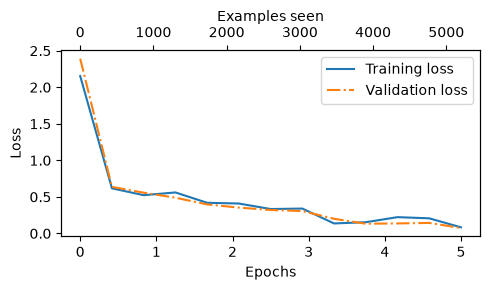

In [243]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

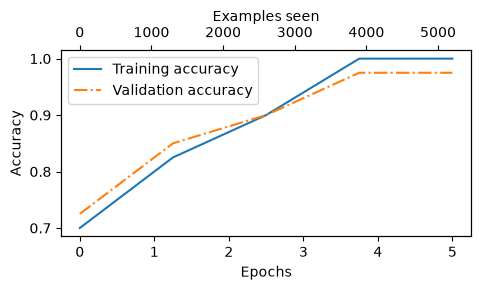

In [244]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))
plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")


In [245]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 97.21%
Validation accuracy: 97.32%
Test accuracy: 95.67%


## Using LLM as a Spam Classifier

In [246]:
def classify_review(text, model, tokenizer, device, max_length=None, 
pad_token_id=50256):
   model.eval()

   # Prepare inputs to the model
   input_ids = tokenizer.encode(text)                            
   supported_context_length = model.pos_emb.weight.shape[1]
    
   input_ids = input_ids[:min(max_length, supported_context_length)] # Truncate sequences if they too long
   input_ids += [pad_token_id] * (max_length - len(input_ids))   # Pad sequences to the longest sequence
   input_tensor = torch.tensor(input_ids, device=device).unsqueeze(0) # Add batch dimension

    
   with torch.no_grad():                                         # Model inference without gradient tracking
       logits = model(input_tensor)[:, -1, :]                    # Logits of the last output token
   predicted_label = torch.argmax(logits, dim=-1).item()
    
   return "spam" if predicted_label == 1 else "not spam"         # Return the classified result

In [251]:
text_1 = (
"Thanks for using the promo code ”NOBIGGIE”. A 10% discount was applied to order #A5124."
    "Your backpack will be delivered on or before 12/12/12."
)
print(classify_review(
   text_1, model, tokenizer, device, max_length=train_dataset.max_length
))

spam


In [248]:
text_2 = (
"Hey, just wanted to check if we're still on"
" for dinner tonight? Let me know!"
)
print(classify_review(
text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


In [249]:
torch.save(model.state_dict(), "review_classifier.pth")

In [250]:
model_state_dict = torch.load("review_classifier.pth")
model.load_state_dict(model_state_dict)

<All keys matched successfully>

In [1]:
print("HelloWORLD")

HelloWORLD


## Instruction Fine-tunning

In [172]:
import json
import os
import urllib
def download_and_load_file(file_path, url):
   if not os.path.exists(file_path):
       with urllib.request.urlopen(url) as response:
           text_data = response.read().decode("utf-8")
       with open(file_path, "w", encoding="utf-8") as file:
           file.write(text_data)
   else:                                                         
       with open(file_path, "r", encoding="utf-8") as file:
           text_data = file.read()
   with open(file_path, "r") as file:
       data = json.load(file)
   return data
file_path = "instruction-data.json"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch07/01_main-chapter-code/instruction-data.json"
data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

Number of entries: 1100


In [173]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [174]:
print("Another example entry:\n", data[999])

Another example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


## Converting Instructions into Alpaca Format

In [175]:
def format_input(entry):
   instruction_text = (
       f"Below is an instruction that describes a task. "
       f"Write a response that appropriately completes the request."
       f"\n\n### Instruction:\n{entry['instruction']}"
   )

   input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
   return instruction_text + input_text

In [176]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [177]:
model_input = format_input(data[999])
desired_response = f"\n\n### Response:\n{data[999]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


In [178]:
train_portion = int(len(data) * 0.85)  # 85% for training
test_portion = int(len(data) * 0.1)   # 10% for testing
val_portion = len(data) - train_portion - test_portion  # Remaining 5% for validation

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


## Step 2 : Organizing data into training batches

In [179]:
import torch
from torch.utils.data import Dataset

class InstructionDataset(Dataset):
   def __init__(self, data, tokenizer):
       self.data = data
       self.encoded_texts = []

       #A Pre-tokenize texts
       for entry in data:                                        
           instruction_plus_input = format_input(entry)
           response_text = f"\n\n### Response:\n{entry['output']}"
           full_text = instruction_plus_input + response_text
           self.encoded_texts.append(
               tokenizer.encode(full_text)
           )
   def __getitem__(self, index):
       return self.encoded_texts[index]
   def __len__(self):
       return len(self.data)

In [180]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


In [181]:
def custom_collate_draft_1(
   batch,
   pad_token_id=50256,
   device="cpu"
):
   # Find the longest sequence in the batch
   batch_max_length = max(len(item)+1 for item in batch)         
   

   # Pad and prepare inputs
   inputs_lst = []

   for item in batch:                                            
       new_item = item.copy()
       # Add an <|endoftext|> token
       new_item += [pad_token_id]
       # Pad sequences to btch_max_length
       padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))

       
       # Remove extra padded token added earlier
       inputs = torch.tensor(padded[:-1])                        
       inputs_lst.append(inputs)

   # Convert list of inputs to tensor and transfer to target device
   inputs_tensor = torch.stack(inputs_lst).to(device)            
   return inputs_tensor

In [182]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]
batch = (
   inputs_1,
   inputs_2,
   inputs_3
)
print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


In [183]:
def custom_collate_draft_2(
   batch,
   pad_token_id=50256,
   device="cpu"
):

   # Find the longest sequence in the batch 
   batch_max_length = max(len(item)+1 for item in batch)

   # Pad and prepare inputs 
   inputs_lst, targets_lst = [], []
   for item in batch:
       # Add an <|endoftext|> token
       new_item = item.copy()
       # Pad sequences to btch_max_length
       new_item += [pad_token_id]
       padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
       inputs = torch.tensor(padded[:-1])    # Truncate the last token for inputs
       targets = torch.tensor(padded[1:])    # Shift +1 to the right for targets 
       inputs_lst.append(inputs)
       targets_lst.append(targets)

   # Concert list of inputs to tensor and transfer to target device 
   inputs_tensor = torch.stack(inputs_lst).to(device)
   targets_tensor = torch.stack(targets_lst).to(device)
   return inputs_tensor, targets_tensor

In [184]:
inputs, targets = custom_collate_draft_2(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


In [185]:
def custom_collate_fn(
   batch,
   pad_token_id=50256,
   ignore_index=-100,
   allowed_max_length=None,
   device="cpu"
):
   batch_max_length = max(len(item)+1 for item in batch)
   inputs_lst, targets_lst = [], []
   for item in batch:
       # Add an <|endoftext|> token
       new_item = item.copy()
       # Pad sequences to btch_max_length
       new_item += [pad_token_id]
       # Pad sequences to max_length
       padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
       inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
       targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

       # Replace all but the first padding tokens in targets by ignore_index
       mask = targets == pad_token_id                            
       indices = torch.nonzero(mask).squeeze()                   
       if indices.numel() > 1:                                   
           targets[indices[1:]] = ignore_index                   

       # Optionally truncate to maximum sequence length
       if allowed_max_length is not None:
           inputs = inputs[:allowed_max_length]                  
           targets = targets[:allowed_max_length]                
       inputs_lst.append(inputs)
       targets_lst.append(targets)

   # Concert list of inputs to tensor and transfer to target device
   inputs_tensor = torch.stack(inputs_lst).to(device)
   targets_tensor = torch.stack(targets_lst).to(device)

   return inputs_tensor, targets_tensor

In [186]:
inputs, targets = custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


In [187]:
logits_1 = torch.tensor(
   [[-1.0, 1.0],  # predictions for 1st token training example
    [-0.5, 1.5]]  # predictions for 2nd token training example
)
targets_1 = torch.tensor([0, 1]) # Correct token indices to generate


loss_1 = torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


In [188]:
logits_2 = torch.tensor(
   [[-1.0, 1.0],
    [-0.5, 1.5],
    [-0.5, 1.5]]          # predictions for 3rd token training example                                       
)
targets_2 = torch.tensor([0, 1, 1])


loss_2 = torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


In [189]:
logits_2 = torch.tensor(
   [[-1.0, 1.0],
    [-0.5, 1.5],
    [-0.5, 1.5]]          # predictions for 3rd token training example                                       
)

targets_3 = torch.tensor([0, 1, -100])

loss_3 = torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)
print("loss_1 == loss_3:", loss_1 == loss_3)

tensor(1.1269)
loss_1 == loss_3: tensor(True)


### Masking Target Token IDS (ORP)

## Step 3 : Creating DataLoaders from an instruction Dataset

In [190]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [191]:
from functools import partial

customized_collate_fn = partial(custom_collate_fn, device=device, allowed_max_length=1024)

In [192]:
from torch.utils.data import DataLoader

num_workers = 0                                                   
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
   train_dataset,
   batch_size=batch_size,
   collate_fn=customized_collate_fn,
   shuffle=True,
   drop_last=True,
   num_workers=num_workers
)

val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
   val_dataset,
   batch_size=batch_size,
   collate_fn=customized_collate_fn,
   shuffle=False,
   drop_last=False,
   num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
test_dataset,
batch_size=batch_size,
collate_fn=customized_collate_fn,
shuffle=False,
drop_last=False,
num_workers=num_workers
)

In [193]:
print("Train loader:")

for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

## Step 4: Loading Pre-trained LLM

In [225]:
from gpt_download3 import download_and_load_gpt2

BASE_CONFIG = {
   "vocab_size": 50257,     # Vocabulary size
   "context_length": 1024,  # Context length
   "drop_rate": 0.0,        # Dropout rate
   "qkv_bias": True         # Query-key-value bias
}

model_configs = {
   "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
   "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
   "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
   "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(
    model_size=model_size, 
    models_dir="gpt2"
)

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\355M\checkpoint


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\355M\encoder.json


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\355M\hparams.json


... (4 outputs left out)

C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\355M\model.ckpt.meta


C:\Users\HP\anaconda3\envs\pytorch311\Lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'openaipublic.blob.core.windows.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


File already exists and is up-to-date: gpt2\355M\vocab.bpe


In [226]:
torch.manual_seed(123)
input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


In [227]:
token_ids = generate(
   model=model,
   idx=text_to_token_ids(input_text, tokenizer),
   max_new_tokens=35,
   context_size=BASE_CONFIG["context_length"],
   eos_id=50256,
)

generated_text = token_ids_to_text(token_ids, tokenizer)

In [228]:
response_text = generated_text[len(input_text):].strip()
print(response_text)

Use rendering verbs to perform a later action: 'Open the door'

Notes: Make sure that either verb has an original, then-position in the verb list.


## Finetunning the model

In [229]:
model.to(device)
torch.manual_seed(123)

with torch.no_grad():
   train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
   val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)
    
print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 3.8258963584899903
Validation loss: 3.761921453475952


In [237]:
import time

start_time = time.time()
torch.manual_seed(123)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)
num_epochs = 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.637, Val loss 2.626
Ep 1 (Step 000005): Train loss 1.174, Val loss 1.102
Ep 1 (Step 000010): Train loss 0.872, Val loss 0.945
Ep 1 (Step 000015): Train loss 0.856, Val loss 0.906
Ep 1 (Step 000020): Train loss 0.776, Val loss 0.881
Ep 1 (Step 000025): Train loss 0.753, Val loss 0.859
Ep 1 (Step 000030): Train loss 0.798, Val loss 0.836
Ep 1 (Step 000035): Train loss 0.714, Val loss 0.808
Ep 1 (Step 000040): Train loss 0.672, Val loss 0.806
Ep 1 (Step 000045): Train loss 0.633, Val loss 0.790
Ep 1 (Step 000050): Train loss 0.662, Val loss 0.783
Ep 1 (Step 000055): Train loss 0.760, Val loss 0.764
Ep 1 (Step 000060): Train loss 0.719, Val loss 0.743
Ep 1 (Step 000065): Train loss 0.652, Val loss 0.735
Ep 1 (Step 000070): Train loss 0.532, Val loss 0.729
Ep 1 (Step 000075): Train loss 0.569, Val loss 0.729
Ep 1 (Step 000080): Train loss 0.605, Val loss 0.725
Ep 1 (Step 000085): Train loss 0.509, Val loss 0.709
Ep 1 (Step 000090): Train loss 0.562, Val loss

In [239]:
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots()

    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")

    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")

    ax2 = ax1.twiny()

    ax2.plot(tokens_seen, train_losses, alpha=0)
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()
    plt.show()

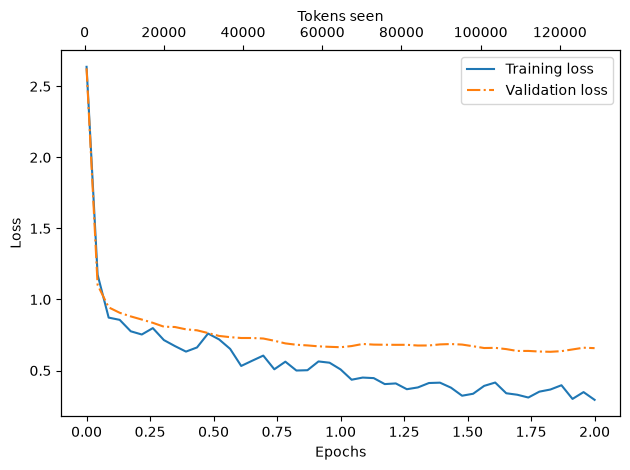

In [240]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))

plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

## Evaluating the performance of LLM

In [241]:
torch.manual_seed(123)

# Iterate over the first 3 test set samples
for entry in test_data[:3]:                                       
   input_text = format_input(entry)
   token_ids = generate(                                         
       model=model,
       idx=text_to_token_ids(input_text, tokenizer).to(device),
       max_new_tokens=256,
       context_size=BASE_CONFIG["context_length"],
       eos_id=50256
   )
   generated_text = token_ids_to_text(token_ids, tokenizer)
   response_text = generated_text[len(input_text):].replace("### Response:", "").strip()
    
   print(input_text)
   print(f"\nCorrect response:\n>> {entry['output']}")
   print(f"\nModel response:\n>> {response_text.strip()}")
   print("-------------------------------------")

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What type of cloud is typically associated with thunderstorms?

Correct response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> A thunderstorm is typically associated with a persistent, unstable low pressure system that produces a series of thunderstorms overland over the night.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Name the author of 'Pride and Prejudice'.


In [242]:
from tqdm import tqdm

for i, entry in tqdm(enumerate(test_data), total=len(test_data)):
   input_text = format_input(entry)
   token_ids = generate(
       model=model,
       idx=text_to_token_ids(input_text, tokenizer).to(device),
       max_new_tokens=256,
       context_size=BASE_CONFIG["context_length"],
       eos_id=50256
   )
    
   generated_text = token_ids_to_text(token_ids, tokenizer)
   response_text = generated_text[len(input_text):].replace("### Response:", "").strip()
    
   test_data[i]["model_response"] = response_text
    
with open("instruction-data-with-response.json", "w") as file:
   json.dump(test_data, file, indent=4)  # "indent" for pretty-printing

100%|██████████| 110/110 [24:20<00:00, 13.27s/it]


In [244]:
print(test_data[67])

{'instruction': "Split the following sentence into two declarative sentences: 'The movie was long but interesting.'", 'input': '', 'output': 'The movie was long. It was interesting.', 'model_response': 'The movie was long and interesting.'}


In [245]:
import re

file_name = f"{re.sub(r'[ ()]', '', CHOOSE_MODEL) }-sft.pth"
torch.save(model.state_dict(), file_name)
print(f"Model saved as {file_name}")

# The saved model can then be loaded via 
# model.load_state_dict(torch.load("gpt2-medium355M-sft.pth"))

Model saved as gpt2-medium355M-sft.pth


## Step 7: EVALUATING THE FINE-TUNED LLM 

In [246]:
import psutil

def check_if_running(process_name):
   running = False
   for proc in psutil.process_iter(["name"]):
       if process_name in proc.info["name"]:
           running = True
           break
   return running
    
ollama_running = check_if_running("ollama")

if not ollama_running:
   raise RuntimeError("Ollama not running. Launch ollama before proceeding.")
print("Ollama running:", check_if_running("ollama"))

Ollama running: True


In [248]:
import json
from tqdm import tqdm

file_path = "instruction-data-with-response.json"
with open(file_path, "r") as file:
    test_data = json.load(file)
    
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    return instruction_text + input_text

In [249]:
import urllib.request

def query_model(prompt, model="llama3", url="http://localhost:11434/api/chat"):
   # Create the data payload as a dictionary
   data = {                                                    
       "model": model,
       "seed": 123,        # for deterministic responses
       "temperature": 0,   # for deterministic responses
       "messages": [
           {"role": "user", "content": prompt}
       ]
   }

   # Convert the dictionary to a JSON formatted string and encode it to bytes 
   payload = json.dumps(data).encode("utf-8")  

   # Create a request object, setting the method to POST and adding necessary headers 
   request = urllib.request.Request(url, data=payload, method="POST") 
   request.add_header("Content-Type", "application/json")   

   # Send the request and capture the response 
   response_data = ""
   with urllib.request.urlopen(request) as response:             
       while True:
           line = response.readline().decode("utf-8")
           if not line:
               break
           response_json = json.loads(line)
           response_data += response_json["message"]["content"]
           
   return response_data

In [250]:
model = "llama3"
result = query_model("What do Llamas eat?", model)
print(result)

Llamas are herbivores, which means they primarily eat plants and plant-based foods. Their diet typically consists of:

1. Grasses: Llamas love to graze on various types of grasses, including tall grasses, short grasses, and grassy meadows.
2. Hay: Hay, such as timothy hay or alfalfa hay, is a staple in a llama's diet. It provides essential fiber, protein, and energy.
3. Fruits and vegetables: Llamas enjoy a variety of fruits and vegetables, including apples, carrots, sweet potatoes, and leafy greens like lettuce and spinach.
4. Grains: Some llamas are fed grains like oats, corn, and barley, which provide additional fiber, energy, and nutrients.
5. Minerals: Llamas need access to mineral supplements, such as calcium, phosphorus, and salt, to maintain strong bones and overall health.
6. Browse: Browse refers to the leaves, twigs, and stems of shrubs and trees. Llamas often browse on plants like sagebrush, cactus, and mesquite.

In their natural habitats, llamas may eat whatever is availa

In [251]:
for entry in test_data[:3]:
   prompt = (
       f"Given the input `{format_input(entry)}` "
       f"and correct output `{entry['output']}`, "
       f"score the model response `{entry['model_response']}`"
       f" on a scale from 0 to 100, where 100 is the best score. "
   )
   print("\nDataset response:")
   print(">>", entry['output'])
   print("\nModel response:")
   print(">>", entry["model_response"])
   print("\nScore:")
   print(">>", query_model(prompt))
   print("\n-------------------------")


Dataset response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet train.

Score:
>> To score the model response, I'll compare it to the correct output "The car is as fast as lightning."

The model response "The car is as fast as a bullet train" is a good attempt to create a simile, but it's not as effective as the correct output. A bullet train is a high-speed train, but it's not as widely recognized or evocative as lightning. Lightning is a vivid and relatable metaphor that conveys a sense of speed and intensity, making it a more effective choice.

I'd score the model response a 70 out of 100. While it's not perfect, it's still a decent attempt at creating a simile, and the comparison to a bullet train is at least somewhat understandable and relatable.

-------------------------

Dataset response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> Types of clouds increase in intensity when they are 

In [252]:
def generate_model_scores(json_data, json_key, model="llama3"):
   scores = []
   for entry in tqdm(json_data, desc="Scoring entries"):
       # Modified instruction line to only return the score
       prompt = (
           f"Given the input `{format_input(entry)}` "
           f"and correct output `{entry['output']}`, "
           f"score the model response `{entry[json_key]}`"
           f" on a scale from 0 to 100, where 100 is the best score. "
           f"Respond with the integer number only."              
       )
       score = query_model(prompt, model)
       try:
           scores.append(int(score))
       except ValueError:
           print(f"Could not convert score: {score}")
           continue
           
   return scores

In [253]:
scores = generate_model_scores(test_data, "model_response")

print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores)/len(scores):.2f}\n")

Scoring entries:  48%|████▊     | 53/110 [04:17<06:46,  7.13s/it]

Could not convert score: Here are the model responses:

### Instruction:
Classify the following items: bicycle, rose, tiger.
Vehicles: Bicycle
Plants: Rose
Animals: Tiger

Score: 100

### Instruction:
Watermelons are typically classified as peaches.
MELONES ARE PESSIMISTATORS
Score: 0


Scoring entries: 100%|██████████| 110/110 [08:56<00:00,  4.88s/it]

Number of scores: 109 of 110
Average score: 46.15

